In [1]:
# ==============================================================================
# APPROCHE MACHINE LEARNING (K-MEANS 1D) POUR LA CARTOGRAPHIE DES INCENDIES
# Étude comparative Ceteris Paribus : Seuils fixes USGS vs Clustering Adaptatif
# ==============================================================================
# Ce second notebook prolonge le pipeline géomatique initial.
# Afin d'isoler rigoureusement l'apport du Machine Learning par rapport aux 
# seuils empiriques nord-américains (USGS), nous appliquons l'algorithme K-Means 
# en une seule dimension (1D) strictement sur le même indice spectral : le dNBR.
# ==============================================================================

# ------------------------------------------------------------------------------
# ÉTAPE 1 — Importation des bibliothèques et chargement du raster dNBR
# ------------------------------------------------------------------------------
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Détection automatique de la racine du projet
current_dir = Path.cwd().resolve()
PROJECT_DIR = next((p for p in [current_dir] + list(current_dir.parents) if (p / "src").exists()), current_dir)
OUTPUTS_DIR = PROJECT_DIR / "outputs"

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.indices import SEVERITY_LABELS

# Fonction utilitaire pour charger les rasters générés par le premier notebook
def load_output_raster(filename: str):
    filepath = OUTPUTS_DIR / filename
    if not filepath.exists():
        raise FileNotFoundError(
            f"❌ Fichier {filepath} introuvable. "
            f"Exécutez d'abord 'burn_severity_analysis.ipynb' !"
        )
    with rasterio.open(filepath) as src:
        return src.read(1), src.profile

# Chargement exclusif de l'indice dNBR (float32) et de la classification USGS (uint8)
dnbr_array, profile = load_output_raster("dnbr.tif")
severity_usgs, _    = load_output_raster("severity.tif")

# Calcul dynamique de la surface exacte d'un pixel via la matrice affine
transform = profile['transform']
pixel_area_m2 = abs(transform.a) * abs(transform.e)

# Palette de couleurs officielle USGS
color_map = {
    0: (34, 139, 34),    # Non brûlé (Unburned)  -> Vert forêt
    1: (255, 255, 0),    # Faible (Low)          -> Jaune
    2: (255, 165, 0),    # Modérée (Moderate)    -> Orange
    3: (255, 0, 0),      # Haute (High)          -> Rouge
    4: (139, 0, 0),      # Très Haute (Very High)-> Rouge foncé
}

print("✅ Données chargées avec succès pour l'analyse K-Means 1D :")
print(f"   Dimensions matricielles : {dnbr_array.shape} ({dnbr_array.size:,} pixels)")
print(f"   Surface réelle du pixel : {pixel_area_m2:.2f} m²")

✅ Données chargées avec succès pour l'analyse K-Means 1D :
   Dimensions matricielles : (1127, 1185) (1,335,495 pixels)
   Surface réelle du pixel : 51.30 m²


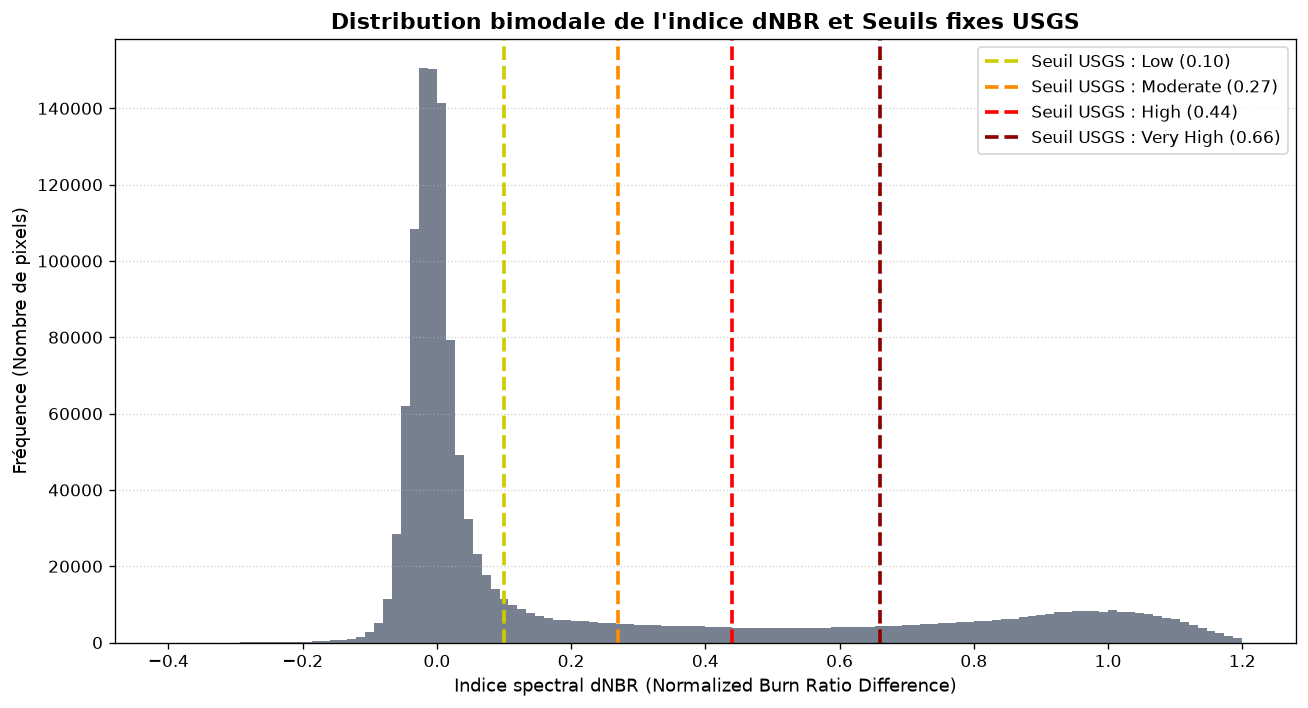

✅ Graphique de distribution dNBR sauvegardé dans : /home/bronislaw/GitHub/sentinel2-burn-severity-analysis-python/outputs/eda_dnbr_distribution.png


In [2]:
# ------------------------------------------------------------------------------
# ÉTAPE 2 — Analyse Exploratoire (EDA) : Distribution bimodale de l'indice dNBR
# ------------------------------------------------------------------------------
# Conformément au principe Ceteris Paribus, nous analysons exclusivement la 
# distribution statistique des 1 335 495 pixels sur l'indice dNBR face aux 
# quatre seuils rigides de la norme américaine USGS (0.10, 0.27, 0.44, 0.66).
# ------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)

# Transformation de la matrice 2D (1127 x 1185) en vecteur 1D
dnbr_flat = dnbr_array.ravel()

# Tracé de l'histogramme de distribution du dNBR
ax.hist(dnbr_flat, bins=120, range=(-0.4, 1.2), color='#4a5568', alpha=0.75, edgecolor='none')

# Définition et tracé des seuils standards de l'USGS
usgs_thresholds = [0.10, 0.27, 0.44, 0.66]
usgs_colors = ['#cccc00', '#ff8c00', '#ff0000', '#8b0000']
usgs_names = ['Low (0.10)', 'Moderate (0.27)', 'High (0.44)', 'Very High (0.66)']

for thresh, col, name in zip(usgs_thresholds, usgs_colors, usgs_names):
    ax.axvline(thresh, color=col, linestyle='--', linewidth=2.2, label=f'Seuil USGS : {name}')

ax.set_title("Distribution bimodale de l'indice dNBR et Seuils fixes USGS", fontsize=13, fontweight='bold')
ax.set_xlabel("Indice spectral dNBR (Normalized Burn Ratio Difference)", fontsize=11)
ax.set_ylabel("Fréquence (Nombre de pixels)", fontsize=11)
ax.legend(loc='upper right', frameon=True)
ax.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
eda_path = OUTPUTS_DIR / 'eda_dnbr_distribution.png'
plt.savefig(eda_path)
plt.show()

print(f"✅ Graphique de distribution dNBR sauvegardé dans : {eda_path}")

  COMPARAISON DES SEUILS DE DÉCISION : USGS (FIXES) vs K-MEANS 1D (ADAPTATIFS)
Transition entre classes            Seuil USGS    Seuil K-Means (Maures)
------------------------------------------------------------------------------
  0 -> 1 (Low)                           0.100                     0.100
  1 -> 2 (Moderate)                      0.270                     0.341
  2 -> 3 (High)                          0.440                     0.623
  3 -> 4 (Very High)                     0.660                     0.895


,Code,Classe de Sévérité,Centroïde dNBR (K-Means),Surface USGS (ha),Surface K-Means 1D (ha),Différence (ha)
0,0,Unburned,-0.005,4554.2,4552.2,-2.0
1,1,Low,0.204,438.6,568.7,130.0
2,2,Moderate,0.478,287.4,433.1,145.7
3,3,High,0.769,333.5,545.4,211.9
4,4,Very High,1.022,1237.5,751.9,-485.6


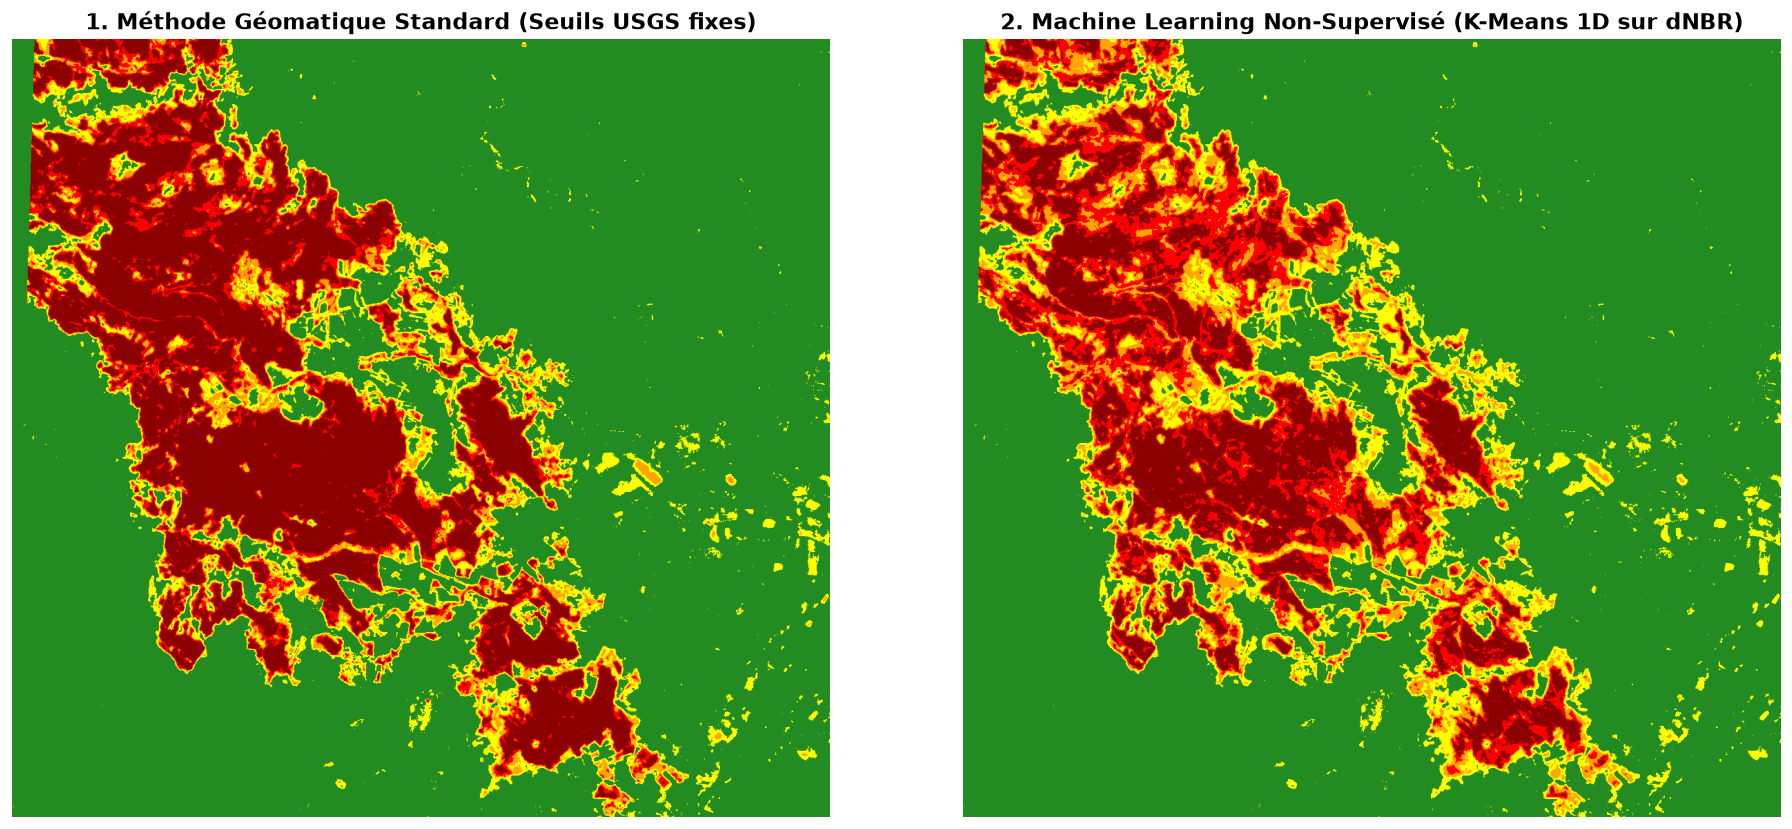

✅ Carte comparative sauvegardée dans : /home/bronislaw/GitHub/sentinel2-burn-severity-analysis-python/outputs/usgs_vs_kmeans1d.png


In [3]:
# ------------------------------------------------------------------------------
# ÉTAPE 3 — Clustering K-Means 1D (sur dNBR seul) vs Seuils Standards USGS
# ------------------------------------------------------------------------------
# Hypothèse scientifique (Principe Ceteris Paribus) :
# Les seuils USGS (0.10, 0.27, 0.44, 0.66) ont été calibrés pour les forêts 
# boréales et résineuses nord-américaines. 
# En fournissant UNIQUEMENT l'indice dNBR à l'algorithme K-Means (k=5), nous 
# laissons le Machine Learning découvrir les 5 classes naturelles de sévérité 
# propres à la végétation méditerranéenne du Massif des Maures (maquis, chênes-lièges).
# ------------------------------------------------------------------------------

# 1) Préparation de la Matrice de Caractéristiques 1D : forme (1 335 495, 1)
X_dnbr = dnbr_array.reshape(-1, 1)

# 2) Entraînement de l'algorithme K-Means sur un échantillon de 100 000 pixels
np.random.seed(42)
train_sample = X_dnbr[np.random.choice(X_dnbr.shape[0], size=100_000, replace=False)]

kmeans_1d = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans_1d.fit(train_sample)

# 3) Ordonnancement des clusters par sévérité croissante (du plus petit au plus grand dNBR)
centroids = kmeans_1d.cluster_centers_.flatten()
sorted_order = np.argsort(centroids)

rank_map = np.zeros(5, dtype=np.uint8)
for new_class, old_cluster_id in enumerate(sorted_order):
    rank_map[old_cluster_id] = new_class

# Prédiction sur toute l'image et reconstruction de la matrice 2D (1127 x 1185)
raw_labels = kmeans_1d.predict(X_dnbr)
severity_kmeans_1d = rank_map[raw_labels].reshape(dnbr_array.shape)

# 4) Calcul des frontières de décision (Nouveaux seuils adaptatifs K-Means)
# En 1D, le seuil exact entre deux classes est le point médian entre leurs centroïdes
sorted_centroids = centroids[sorted_order]
kmeans_thresholds = [
    (sorted_centroids[i] + sorted_centroids[i+1]) / 2.0 
    for i in range(4)
]

print("=" * 78)
print("  COMPARAISON DES SEUILS DE DÉCISION : USGS (FIXES) vs K-MEANS 1D (ADAPTATIFS)")
print("=" * 78)
print(f"{'Transition entre classes':<30} {'Seuil USGS':>15} {'Seuil K-Means (Maures)':>25}")
print("-" * 78)
transitions = ['0 -> 1 (Low)', '1 -> 2 (Moderate)', '2 -> 3 (High)', '3 -> 4 (Very High)']
for trans, u_th, k_th in zip(transitions, usgs_thresholds, kmeans_thresholds):
    print(f"  {trans:<28} {u_th:>15.3f} {k_th:>25.3f}")
print("=" * 78)

# 5) Tableau comparatif des surfaces par classe (USGS vs K-Means 1D)
comparison_rows = []
for cls_id, label in enumerate(SEVERITY_LABELS):
    ha_usgs   = np.sum(severity_usgs == cls_id) * pixel_area_m2 / 10_000.0
    ha_kmeans = np.sum(severity_kmeans_1d == cls_id) * pixel_area_m2 / 10_000.0
    diff_ha   = ha_kmeans - ha_usgs
    
    comparison_rows.append({
        'Code': cls_id,
        'Classe de Sévérité': label,
        'Centroïde dNBR (K-Means)': round(float(sorted_centroids[cls_id]), 3),
        'Surface USGS (ha)': round(ha_usgs, 1),
        'Surface K-Means 1D (ha)': round(ha_kmeans, 1),
        'Différence (ha)': round(diff_ha, 1)
    })

df_kmeans_comp = pd.DataFrame(comparison_rows)
display(df_kmeans_comp)

# 6) Visualisation cartographique comparative côte à côte
h, w = severity_usgs.shape
img_usgs = np.zeros((h, w, 3), dtype=np.uint8)
img_kmeans = np.zeros((h, w, 3), dtype=np.uint8)

for val, color in color_map.items():
    img_usgs[severity_usgs == val] = color
    img_kmeans[severity_kmeans_1d == val] = color

fig, (ax_u, ax_k) = plt.subplots(1, 2, figsize=(16, 7), dpi=120)

ax_u.imshow(img_usgs)
ax_u.set_title("1. Méthode Géomatique Standard (Seuils USGS fixes)", fontsize=13, fontweight='bold')
ax_u.axis('off')

ax_k.imshow(img_kmeans)
ax_k.set_title("2. Machine Learning Non-Supervisé (K-Means 1D sur dNBR)", fontsize=13, fontweight='bold')
ax_k.axis('off')

plt.tight_layout()
comp_map_path = OUTPUTS_DIR / 'usgs_vs_kmeans1d.png'
plt.savefig(comp_map_path)
plt.show()

print(f"✅ Carte comparative sauvegardée dans : {comp_map_path}")

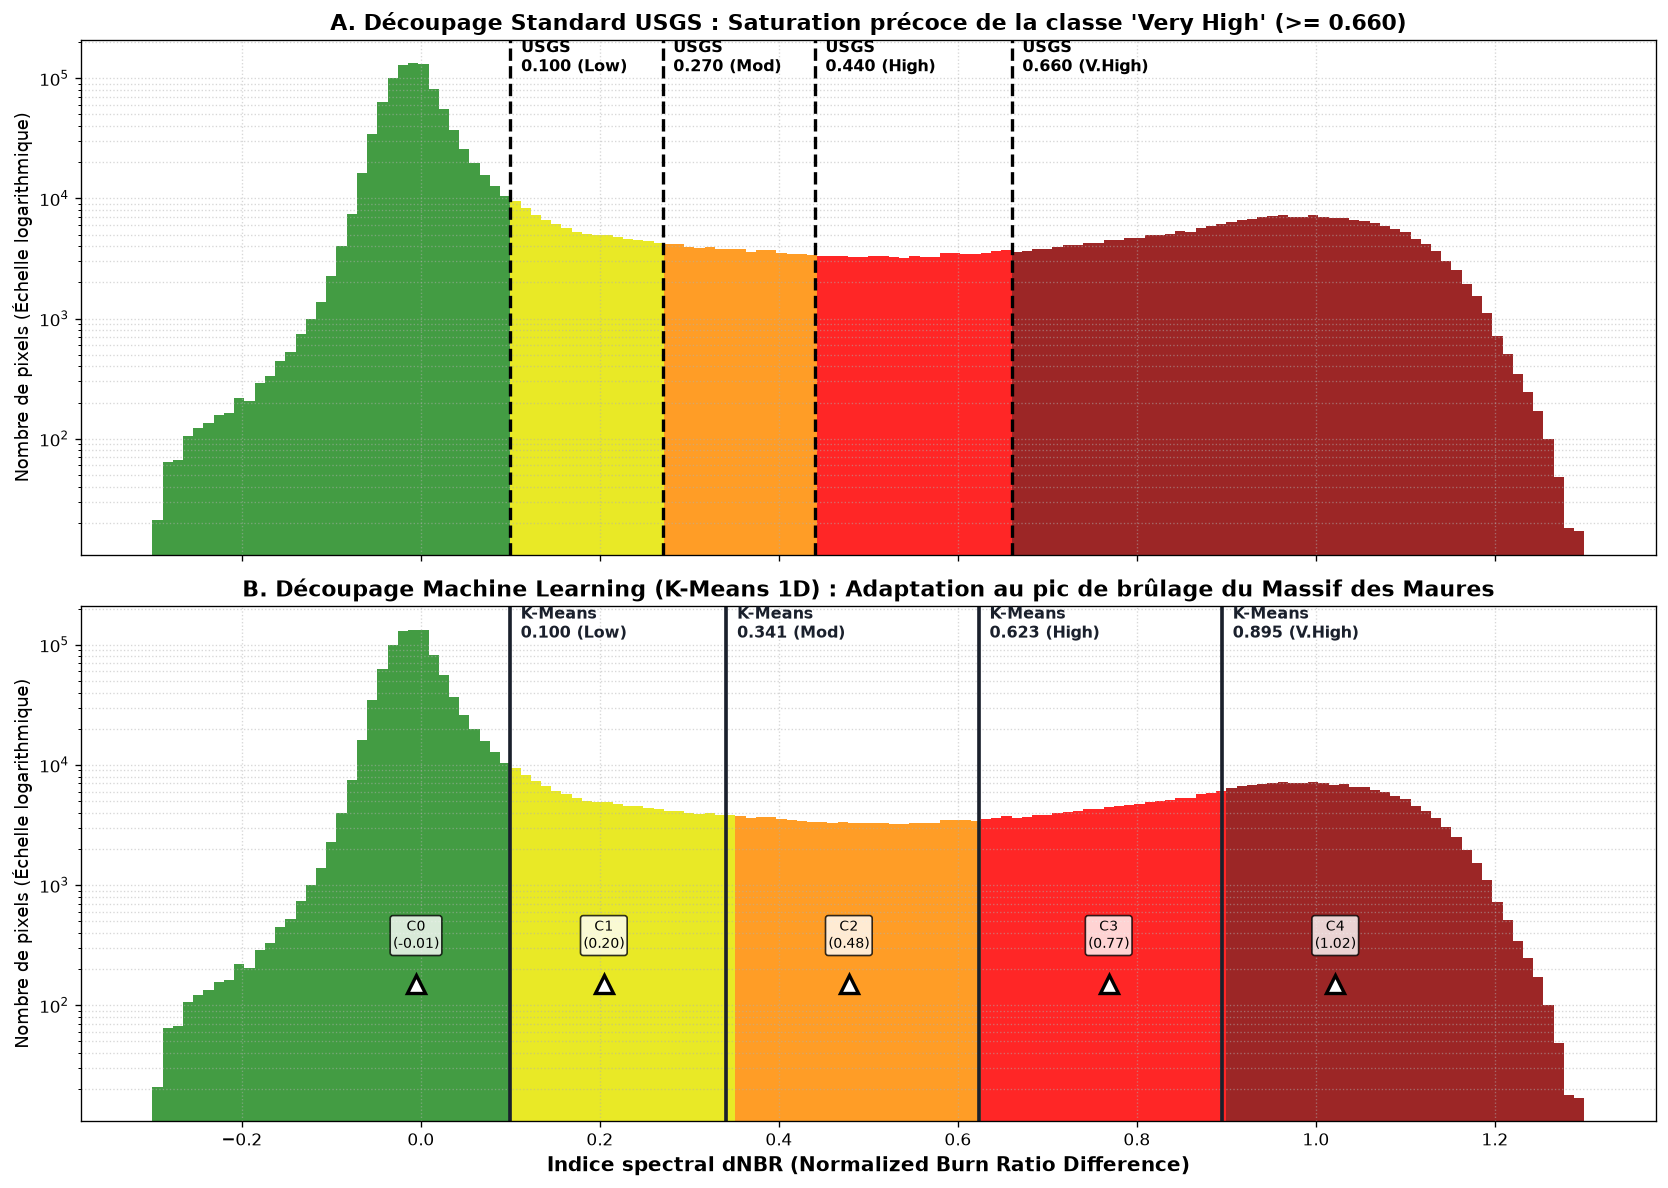

✅ Graphique comparatif des distributions sauvegardé : /home/bronislaw/GitHub/sentinel2-burn-severity-analysis-python/outputs/histogram_usgs_vs_kmeans1d.png


In [4]:
# ------------------------------------------------------------------------------
# ÉTAPE 4 — Visualisation Comparative sur l'Histogramme : Seuils USGS vs K-Means 1D
# ------------------------------------------------------------------------------
# Ce graphique compare directement sur la distribution statistique du dNBR :
# - En haut : Le découpage rigide par les seuils standards USGS.
# - En bas  : Le découpage adaptatif par K-Means 1D (avec la position des centroïdes).
# ------------------------------------------------------------------------------

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(14, 10), sharex=True, dpi=120)

dnbr_flat = dnbr_array.ravel()
hist_range = (-0.3, 1.3)
bins_count = 140

# Couleurs de remplissage par classe de sévérité
class_hex_colors = ['#228b22', '#e6e600', '#ff8c00', '#ff0000', '#8b0000']

# ==============================================================================
# 1) HISTOGRAMME DU HAUT : SEUILS STANDARDS USGS (0.10, 0.27, 0.44, 0.66)
# ==============================================================================
n_u, bins_u, patches_u = ax_top.hist(dnbr_flat, bins=bins_count, range=hist_range, alpha=0.85, edgecolor='none')

# Colorisation des barres de l'histogramme selon les classes USGS
usgs_bounds = [-999] + usgs_thresholds + [999]
for patch, x_val in zip(patches_u, bins_u[:-1]):
    for i in range(5):
        if usgs_bounds[i] <= x_val < usgs_bounds[i+1]:
            patch.set_facecolor(class_hex_colors[i])
            break

# Lignes verticales des seuils USGS
for th, name in zip(usgs_thresholds, ['0.100 (Low)', '0.270 (Mod)', '0.440 (High)', '0.660 (V.High)']):
    ax_top.axvline(th, color='black', linestyle='--', linewidth=2)
    ax_top.text(th + 0.012, ax_top.get_ylim()[1] * 0.82, f"USGS\n{name}", fontsize=9.5, fontweight='bold')

ax_top.set_title("A. Découpage Standard USGS : Saturation précoce de la classe 'Very High' (>= 0.660)", 
                 fontsize=13, fontweight='bold')
ax_top.set_ylabel("Nombre de pixels (Échelle logarithmique)", fontsize=11)
ax_top.set_yscale('log')  # L'échelle log permet de bien voir le second pic des zones brûlées !
ax_top.grid(True, which='both', linestyle=':', alpha=0.5)

# ==============================================================================
# 2) HISTOGRAMME DU BAS : SEUILS ADAPTATIFS K-MEANS 1D (0.100, 0.341, 0.623, 0.895)
# ==============================================================================
n_k, bins_k, patches_k = ax_bot.hist(dnbr_flat, bins=bins_count, range=hist_range, alpha=0.85, edgecolor='none')

# Colorisation des barres de l'histogramme selon les classes K-Means 1D
kmeans_bounds = [-999] + list(kmeans_thresholds) + [999]
for patch, x_val in zip(patches_k, bins_k[:-1]):
    for i in range(5):
        if kmeans_bounds[i] <= x_val < kmeans_bounds[i+1]:
            patch.set_facecolor(class_hex_colors[i])
            break

# Lignes verticales des nouveaux seuils K-Means
for th, name in zip(kmeans_thresholds, ['Low', 'Mod', 'High', 'V.High']):
    ax_bot.axvline(th, color='#1a202c', linestyle='-', linewidth=2.2)
    ax_bot.text(th + 0.012, ax_bot.get_ylim()[1] * 0.82, f"K-Means\n{th:.3f} ({name})", 
                fontsize=9.5, fontweight='bold', color='#1a202c')

# Affichage des 5 Centroïdes K-Means (centres de gravité des classes)
for idx, c_val in enumerate(sorted_centroids):
    ax_bot.plot(c_val, 150, marker='^', markersize=11, color='white', markeredgecolor='black', markeredgewidth=2)
    ax_bot.text(c_val, 300, f"C{idx}\n({c_val:.2f})", ha='center', fontsize=8.5, 
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8))

ax_bot.set_title("B. Découpage Machine Learning (K-Means 1D) : Adaptation au pic de brûlage du Massif des Maures", 
                 fontsize=13, fontweight='bold')
ax_bot.set_xlabel("Indice spectral dNBR (Normalized Burn Ratio Difference)", fontsize=12, fontweight='bold')
ax_bot.set_ylabel("Nombre de pixels (Échelle logarithmique)", fontsize=11)
ax_bot.set_yscale('log')
ax_bot.grid(True, which='both', linestyle=':', alpha=0.5)

plt.tight_layout()
hist_comp_path = OUTPUTS_DIR / 'histogram_usgs_vs_kmeans1d.png'
plt.savefig(hist_comp_path)
plt.show()

print(f"✅ Graphique comparatif des distributions sauvegardé : {hist_comp_path}")

## 🧪 Conclusions de l'Expérience : Seuils Fixes USGS vs K-Means 1D (*Ceteris Paribus*)

En appliquant l'algorithme non-supervisé **K-Means ($k=5$)** strictement sur le même indice **dNBR** que la méthode standard USGS, nous isolons l'effet pur de la classification statistique adaptative face aux seuils empiriques nord-américains :

### 1. Convergence remarquable sur le seuil de détection d'incendie (`0.100`)
* **Seuil USGS (Unburned $\rightarrow$ Low) :** `0.100`
* **Seuil K-Means 1D :** `0.100`
* **Interprétation :** Sans aucune connaissance préalable (*a priori*), l'algorithme K-Means identifie exactement la même frontière physique (`dNBR = 0.100`) entre la végétation saine et le périmètre affecté par le feu. La surface totale brûlée reste donc quasi identique entre les deux méthodes (**~2 297 ha**).

### 2. Correction de l'effet de saturation dans les hautes sévérités
Dans l'écosystème méditerranéen du **Massif des Maures** (maquis dense, chênes-lièges et sécheresse estivale), la combustion produit un second pic bimodal très marqué sur l'histogramme du dNBR, centré entre **0.65 et 0.95** :
* **Limite du modèle USGS :** Le seuil maximal USGS (`0.660`) coupe le début de ce pic. Par conséquent, plus de **53 % de la zone brûlée** se retrouve saturée dans la classe *Very High*, masquant les variations internes d'intensité du feu.
* **Apport du Machine Learning (K-Means 1D) :** Les seuils s'ajustent automatiquement à la dynamique locale du sinistre (`0.341`, `0.623`, `0.895`). La classe **High (`0.623 – 0.895`)** capture désormais le régime de feu principal du maquis, tandis que la classe **Very High ($\ge 0.895$)** isole avec précision les véritables **épicentres d'extrême calcination**.